# K-Means Clustering（K-Means 分群）

K-Means 是一種 **Unsupervised Learning（非監督式學習）**演算法，主要用於 Clustering（分群）。

它會根據資料之間的相似程度，將資料分成 K 個群集。

例如，一間商店擁有 500 位顧客，每位顧客都有以下資料：

```text
每月收入
每月來店次數
每月消費金額
```

商店希望知道：「這 500 位顧客能不能根據消費習慣，自動分成幾個具有不同特徵的群體？」

K-Means 可以協助找出這些群體。

$$\boxed{ \text{顧客消費資料} \longrightarrow \text{K-Means} \longrightarrow \text{顧客分群} } $$

例如模型可能找出：

| 群集        | 消費特徵           | 可能的商業解讀 |
| --------- | -------------- | ------- |
| Cluster 0 | 收入較低、消費較少、來店較少 | 低活躍顧客   |
| Cluster 1 | 收入中等、消費中等、來店頻繁 | 忠誠顧客    |
| Cluster 2 | 收入較高、消費較高      | 高價值顧客   |
| Cluster 3 | 收入中等、來店非常頻繁    | 高頻率顧客   |

這些群集名稱不是 K-Means 自動理解出來的，而是我們根據分群結果進行解釋。


### Cluster（群集）是什麼？

![](./assets/Cluster.png)


### Centroid（群中心）

![](./assets/Centroid.png)

### K-Means 的運作流程

K-Means 的核心流程可以拆成五個步驟。

1. 決定 K 值

   例如 K=3，代表希望將資料分成三個群集。
2. 初始化三個 Centroid

   模型先選擇三個初始群中心。
3. 分配資料到最近的 Centroid

   計算每筆資料與各群中心的距離，分配給最近的群集。
4. 重新計算 Centroid

   根據目前分配到每個群的資料，重新計算平均位置。
5. 重複分配與更新

   直到群中心幾乎不再移動，或達到最大迭代次數。

這個過程可以理解為：

```
設定 K
   ↓
初始化 Centroid
   ↓
計算資料與 Centroid 的距離
   ↓
將資料分配到最近的群
   ↓
重新計算每群 Centroid
   ↓
是否收斂？
   ├── 否 → 繼續重新分配資料
   └── 是 → 完成分群
```

### WCSS（Within-Cluster Sum of Squares）

![](./assets/WCSS.png)

### Elbow Method（手肘法）

![](./assets/Elbow_Method.png)

### 為什麼 K-Means 通常需要 StandardScaler？

K-Means 主要根據距離進行分群，因此不同 Features 的數值尺度會影響結果。

假設顧客資料：

| Feature | 數值範圍           |
| ------- | -------------- |
| 每月收入    | 20,000～120,000 |
| 每月來店次數  | 1～20           |
| 每月消費金額  | 500～15,000     |

如果直接計算距離，收入的數值範圍遠大於來店次數。

這可能造成模型的分群結果主要受到收入影響，而忽略其他特徵。

因此，我們通常會使用：

```
StandardScaler()
```

將不同 Features 調整到較可比較的尺度。

| 處理前         | 處理後   |
| ----------- | ----- |
| 每月收入：50,000 | 標準化數值 |
| 來店次數：5      | 標準化數值 |
| 消費金額：3,000  | 標準化數值 |

StandardScaler 會將每個 Feature 轉換為平均值約 0、標準差約 1 的尺度。

## KMeans 模型重要參數

```python
from sklearn.cluster import KMeans
model = KMeans(    
	n_clusters=4, # 要分成幾群，也就是 K 值
	init="k-means++", # 初始 Centroid 的選擇方式。k-means++：以較有策略的方式選擇初始群中心
	n_init=10, # 使用不同初始位置執行幾次，保留 WCSS 最小的結果
	max_iter=300, # 每次初始化最多迭代幾次
	tol=1e-4, # 判斷 Centroid 是否收斂的容許程度
	random_state=42
	)
```

### n_init：重複初始化次數

```
n_init=10
```

代表：

1. 使用不同初始 Centroid 執行 K-Means。
2. 總共執行 10 次。
3. 保留其中 WCSS 最小的結果。

K-Means 可能因初始群中心不同而得到不同結果，因此這個參數很重要。

### max_iter：最大迭代次數

```
max_iter=300
```

代表每次初始化最多進行 300 次迭代。

如果提前收斂，就不需要跑滿 300 次。

### tol：收斂容許程度

```
tol=1e-4
```

當群中心的變動程度已經足夠小，模型就可以停止迭代。

一般入門練習使用預設值即可。

### K-Means 常用方法與屬性

| 方法或屬性              | 說明               |
| ------------------ | ---------------- |
| `fit(X)`           | 使用資料訓練模型         |
| `predict(X)`       | 將資料分配到最近的群中心     |
| `fit_predict(X)`   | 訓練模型並回傳群集標籤      |
| `labels_`          | 訓練資料的群集標籤        |
| `cluster_centers_` | 各群 Centroid 的座標  |
| `inertia_`         | 訓練資料的 WCSS       |
| `n_iter_`          | 最佳初始化結果實際執行的迭代次數 |

## 實作：使用 K-Means 進行顧客分群

### 讀取資料集

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 讀取資料集
df = pd.read_csv("./data/kmeans_customer_segments.csv")

### 查看前 10 筆
display(df.head(10))

### 查看資料形狀
print(df.shape)

,customer_id,age,monthly_income,visits_per_month,monthly_spending
0,C0001,30,95316,14,10845
1,C0002,26,31965,4,2458
2,C0003,30,76443,11,8394
3,C0004,36,64715,6,6451
4,C0005,18,30046,4,3466
5,C0006,36,31976,22,2860
6,C0007,54,71278,13,5506
7,C0008,28,24033,3,683
8,C0009,28,41938,4,2598
9,C0010,40,36619,16,3272


(500, 5)


### 探索資料 (EDA)

In [4]:
### 查看資料型態與缺失值
df.info()

### 查看數值欄位的統計資訊
display(df.describe())

### 查看各欄位缺失值數量
print(df.isnull().sum())

### 查看是否存在重複資料
print("重複筆數：", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customer_id       500 non-null    object
 1   age               500 non-null    int64 
 2   monthly_income    500 non-null    int64 
 3   visits_per_month  500 non-null    int64 
 4   monthly_spending  500 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 19.7+ KB


,age,monthly_income,visits_per_month,monthly_spending
count,500.000000,500.000000,500.000000,500.00000
mean,34.500000,58824.226000,8.798000,4774.67400
std,9.843566,25069.792908,4.888455,3289.66156
min,18.000000,18000.000000,1.000000,300.00000
25%,27.000000,38047.500000,4.000000,2055.50000
50%,34.000000,55175.000000,8.500000,3979.00000
75%,42.000000,75561.750000,13.000000,6403.75000
max,63.000000,124243.000000,22.000000,12568.00000


customer_id         0
age                 0
monthly_income      0
visits_per_month    0
monthly_spending    0
dtype: int64
重複筆數： 0


### 資料清理

In [5]:
### 移除完全重複的資料
df = df.drop_duplicates().copy()

### 移除缺少顧客編號的資料
df = df.dropna(subset=["customer_id"])

### 重設索引
df = df.reset_index(drop=True)

### 確認清理結果
print(df.shape)

(500, 5)


### 選擇 Features

In [6]:
### 選擇分群使用的 Features
X = df[[
    "monthly_income",
    "visits_per_month",
    "monthly_spending"
]].copy()

### K-Means 不需要 Target（y）
print(X.shape)
display(X.head())

(500, 3)


,monthly_income,visits_per_month,monthly_spending
0,95316,14,10845
1,31965,4,2458
2,76443,11,8394
3,64715,6,6451
4,30046,4,3466


### 切分 Train / Test

In [7]:
from sklearn.model_selection import train_test_split

### 切分 Train 80%、Test 20%
X_train, X_test = train_test_split(
    X,
    test_size=0.2, # 20% 作為 Test Data
    random_state=42 # 固定隨機種子
)

### 查看資料形狀
print("X_train：", X_train.shape)
print("X_test：", X_test.shape)

X_train： (400, 3)
X_test： (100, 3)


### 建立資料前處理 Pipeline
本次資料只有數值型 Features，因此不需要 OneHotEncoder。

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

### 建立資料前處理流程
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # 缺失值使用中位數補齊
    ("scaler", StandardScaler()) # 將 Features 標準化
])

### 使用 Elbow Method 選擇 K 值
先不要急著設定 n_clusters=4。

我們先使用不同 K 值訓練模型，觀察 WCSS 的變化。

#### 計算不同 K 值的 WCSS

In [9]:
from sklearn.cluster import KMeans

### 只使用 Train Data 擬合前處理器
X_train_scaled = preprocessor.fit_transform(X_train)

### 設定候選 K 值
k_values = range(1, 11)

### 儲存每個 K 的 WCSS
wcss = []

### 依序測試不同 K 值
for k in k_values:

    ### 建立 K-Means 模型
    kmeans = KMeans(
        n_clusters=k, # 目前測試的 K 值
        init="k-means++", # 初始化方式
        n_init=10, # 重複初始化 10 次
        random_state=42 # 固定隨機種子
    )

    ### 訓練模型
    kmeans.fit(X_train_scaled)

    ### 儲存 WCSS
    wcss.append(kmeans.inertia_)

### 顯示結果
wcss_df = pd.DataFrame({
    "K": list(k_values),
    "WCSS": wcss
})

display(wcss_df)

,K,WCSS
0,1,1200.000000
1,2,590.735219
2,3,330.865776
3,4,185.508443
4,5,165.431156
5,6,149.588278
6,7,136.917477
7,8,128.437443
8,9,115.105367
9,10,108.271108


#### 繪製 Elbow Method

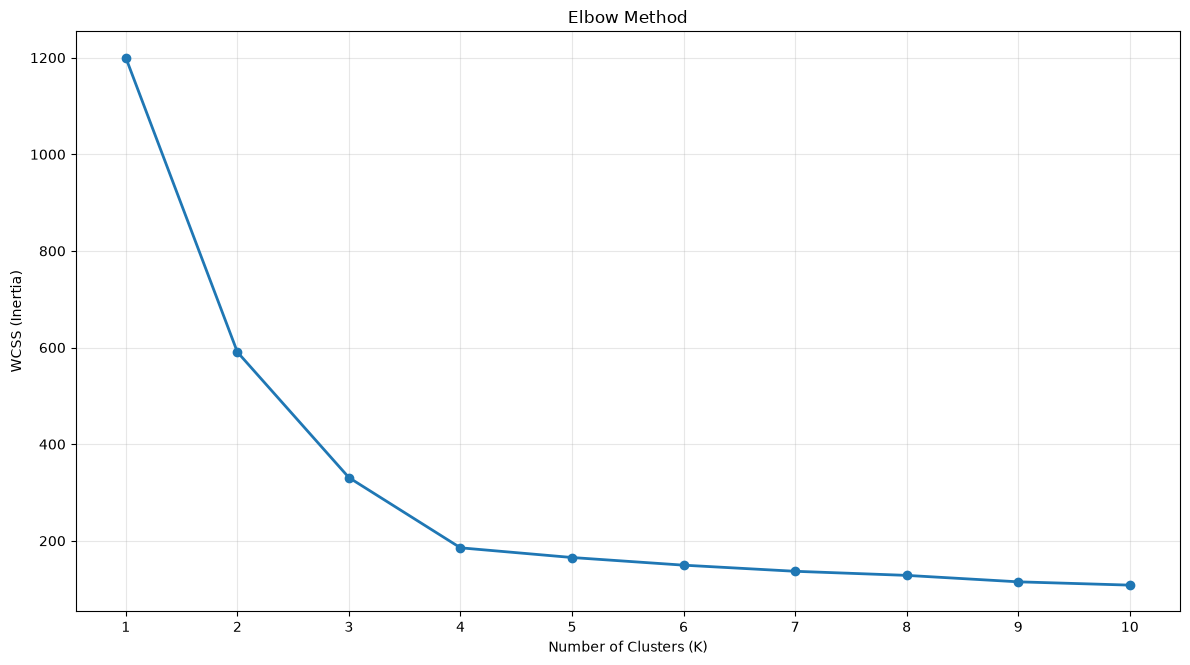

In [10]:
### 建立圖表
plt.figure(figsize=(12, 6.75))

### 繪製 K 與 WCSS 的關係
plt.plot(
    list(k_values), wcss,
    marker="o", # 顯示每個 K 的資料點
    linewidth=2
)

### 設定圖表
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 建立模型

In [13]:
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn import set_config

### 關閉 scikit-learn 模型的 HTML 視覺化顯示
set_config(display="text")

### 建立 K-Means Pipeline
model = Pipeline([
    ("preprocessor", Pipeline([
        ("imputer", SimpleImputer(strategy="median")), # 缺失值補齊
        ("scaler", StandardScaler()) # 特徵標準化
    ])),
    ("kmeans", KMeans(
        n_clusters=4, # 將顧客分成 4 群
        init="k-means++", # 初始化 Centroid
        n_init=10, # 重複初始化 10 次
        max_iter=300, # 最大迭代次數
        tol=1e-4, # 收斂容許程度
        random_state=42 # 固定隨機種子
    ))
])

### 使用 Train Data 訓練 K-Means
model.fit(X_train)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                                 ('scaler', StandardScaler())])),
                ('kmeans', KMeans(n_clusters=4, n_init=10, random_state=42))])

### 使用模型預測群集

In [14]:
### 預測 Test Data 屬於哪個群集
test_clusters = model.predict(X_test)

### 查看前 10 筆群集標籤
print(test_clusters[:10])
# 這些編號不是模型預測的「正確答案」，而是模型依照已學到的 Centroid 分配的群集。

[1 1 1 1 1 1 3 3 3 3]


### 評估 K-Means 分群結果
K-Means 沒有真實 Target，因此通常不使用：
```python
accuracy_score()
precision_score()
recall_score()
f1_score()
confusion_matrix()
```


這些指標主要用於已知真實類別的監督式分類任務。K-Means 常用的評估方式包括：
1. WCSS（群內平方和）(上面已經跑過)
2. Silhouette Score（輪廓係數）
3. 各群樣本數量
4. 各群特徵與實際解釋性

#### Silhouette Score（輪廓係數）

Silhouette Score 是另一個常見的分群評估指標。
它想回答：
同一群內的資料是否夠接近？不同群的資料是否夠分開？

$$
\boxed{-1\leq \text{Silhouette Score}\leq1}
$$

| 分數 | 常見解讀 |
|---|---|
| 接近 1 | 群內集中、群間分離較明顯 |
| 接近 0 | 群集之間可能重疊 |
| 小於 0 | 部分資料可能更接近其他群 |

這只是概念上的解讀，實際上還要考慮資料形狀與應用需求。

#### 查看各群顧客數量

In [17]:
### 將 Test Data 與群集標籤整理在一起
test_result = X_test.copy()

### 加入分群結果
test_result["Cluster"] = test_clusters

### 查看各群數量
print(test_result["Cluster"].value_counts().sort_index())

Cluster
0    23
1    29
2    26
3    22
Name: count, dtype: int64


#### 分析每個群集的特徵

In [18]:
### 計算各群的平均特徵
cluster_summary = test_result.groupby("Cluster")[
    ["monthly_income", "visits_per_month", "monthly_spending"]
].mean()

### 顯示群集特徵
display(cluster_summary.round(2))

,monthly_income,visits_per_month,monthly_spending
Cluster,,,
0,32206.70,2.91,1618.57
1,92012.48,12.10,9877.52
2,49714.46,14.96,2966.65
3,61427.05,7.18,4721.73


### 視覺化分群結果

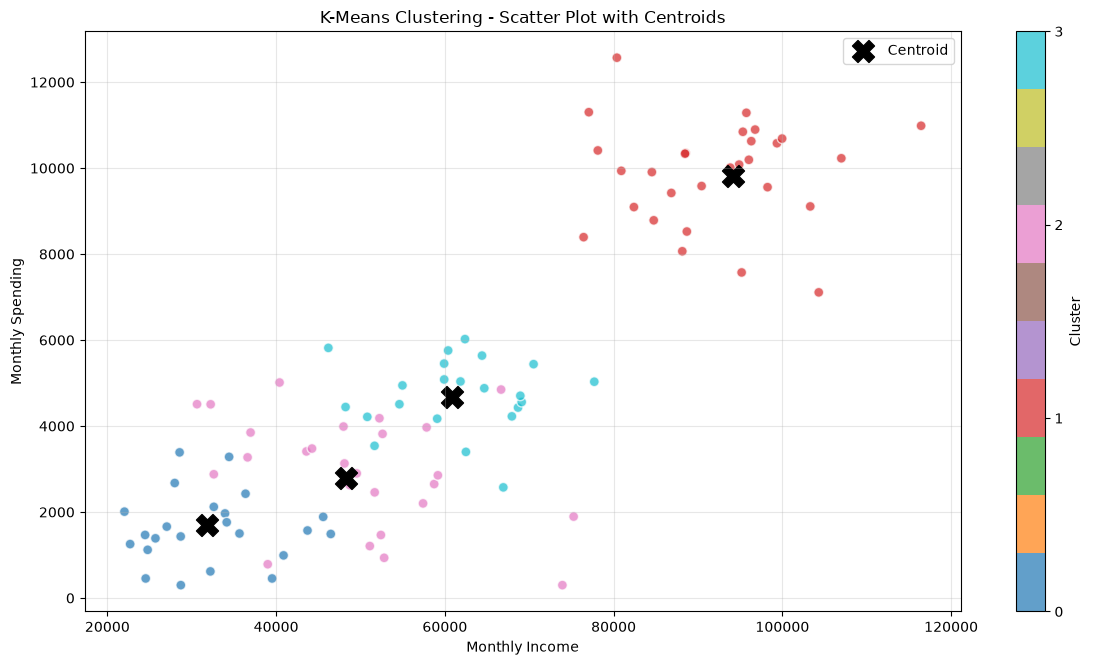

In [25]:
import matplotlib.pyplot as plt

### 使用模型預測 Test Data 的群集
test_clusters = model.predict(X_test)

### 取得 K-Means 模型
kmeans = model.named_steps["kmeans"]

### 取得 StandardScaler
scaler = model.named_steps["preprocessor"].named_steps["scaler"]

### 將 Centroid 還原成原始數值
centers = scaler.inverse_transform(kmeans.cluster_centers_)


### 建立圖表
plt.figure(figsize=(12, 6.75))

### 繪製各群資料點
scatter = plt.scatter(
    X_test["monthly_income"], # X 軸：每月收入
    X_test["monthly_spending"], # Y 軸：每月消費金額
    c=test_clusters, # 根據 Cluster 編號設定顏色
    cmap="tab10", # 使用不同顏色區分群集
    s=50, # 散點大小
    alpha=0.7, # 透明度
    edgecolors="white"
)

### 繪製 Centroid
plt.scatter(
    centers[:, 0], # Centroid 的每月收入
    centers[:, 2], # Centroid 的每月消費金額
    marker="X", # 使用 X 標記群中心
    c="black", # 黑色
    s=250, # 群中心大小
    label="Centroid"
)

### 設定圖表
plt.xlabel("Monthly Income")
plt.ylabel("Monthly Spending")
plt.title("K-Means Clustering - Scatter Plot with Centroids")
plt.colorbar(scatter, ticks=range(kmeans.n_clusters), label="Cluster")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 作業：使用 K-Means Clustering 分析臺南市旅館資源分布

本次作業使用政府資料開放平臺提供的「臺南市旅館家數統計」，並使用 K-Means Clustering（K-Means 分群）建立模型，根據各行政區的旅館家數與客房數，分析臺南市不同行政區的旅館資源分布特徵。

- 資料集：[臺南市旅館家數統計](https://data.gov.tw/dataset/143155)
- 資料提供機關：臺南市政府觀光旅遊局
- 資料格式：CSV / JSON，依平台提供的年度資源下載。

政府資料集提供行政區、一般旅館家數、一般旅館客房數、國際觀光旅館家數、一般觀光旅館家數及相應客房數等欄位。

### 作業目標

根據臺南市各行政區的旅館統計資料，例如：

```text
一般旅館家數
一般旅館客房數
國際觀光旅館家數
國際觀光旅館客房數
一般觀光旅館家數
一般觀光旅館客房數
```

進行分群：

```text
Cluster 0 → 某種旅館資源特徵
Cluster 1 → 另一種旅館資源特徵
Cluster 2 → 另一種旅館資源特徵
...
```

建立以下關係：
$$
\boxed{ \text{各行政區旅館家數與客房數} \longrightarrow \text{K-Means Clustering} \longrightarrow \text{行政區旅館資源分群} }
$$

這次作業不是預測未來旅館數量，也不是判斷哪個行政區比較好，而是使用 K-Means 探索行政區之間的旅館資源結構。

### Features 與 Target

| 欄位          | 用途      | 說明                 |
| ----------- | ------- | ------------------ |
| `行政區`       | 識別欄位    | 用於顯示分群結果，不參與訓練     |
| `一般旅館家數`    | Feature | 一般旅館數量             |
| `一般旅館客房數`   | Feature | 一般旅館房間數            |
| `國際觀光旅館家數`  | Feature | 國際觀光旅館數量           |
| `國際觀光旅館客房數` | Feature | 國際觀光旅館房間數          |
| `一般觀光旅館家數`  | Feature | 一般觀光旅館數量           |
| `一般觀光旅館客房數` | Feature | 一般觀光旅館房間數          |
| Target      | 無       | K-Means 不需要 Target |

實際欄位名稱請以下載檔案為準。政府資料中的部分欄位可能使用底線連接，學生應先使用 `df.columns` 確認。

重要提醒： 行政區名稱不能直接當成一般數值特徵。若某行政區沒有特定類型旅館，數值 0 代表真實的零家；不能一律當成缺失值。

### 學生 Notebook 必須按照以下順序完成

```text
1. Pandas 讀取政府開放資料
        ↓
2. 探索資料 (head / info / describe)
        ↓
3. 資料清理
        ↓
4. 選擇 Features（不需要 Target）
        ↓
5. Train / Test Split
        ↓
6. 建立資料前處理 Pipeline
   (SimpleImputer / StandardScaler)
        ↓
7. 使用 Elbow Method 選擇 K 值
        ↓
8. 建立 K-Means 模型
        ↓
9. 訓練模型
        ↓
10. 使用模型進行分群
        ↓
11. 評估分群結果
    (WCSS / Silhouette Score)
        ↓
12. 視覺化
    (Elbow Method / Scatter Plot)
        ↓
13. 分析各群行政區的旅館資源特徵
```

### 作業要求

1. 使用 Pandas 讀取政府開放資料，並顯示前 10 筆。
2. 使用 `info()`、`describe()`、`isnull().sum()` 探索資料。
3. 清理重複資料、缺失值與非數值欄位。
4. 選擇至少四個與旅館資源有關的數值 Features。
5. 使用 Train 80%、Test 20% 切分資料；不需要 `y` 或 `stratify`。
6. 使用 `SimpleImputer`、`StandardScaler` 建立前處理 Pipeline。
7. 使用 Elbow Method 比較 K=2～5 的 WCSS。
8. 使用 `KMeans(n_clusters=自行選擇, n_init=10, random_state=42)` 建立模型。
9. 使用 `fit()` 訓練模型，使用 `predict()` 分配 Test Data 的群集。
10. 計算 WCSS 與 Silhouette Score，並解釋結果。
11. 繪製 Elbow Method 與二維 Scatter Plot。
12. 使用 `groupby("Cluster").mean()` 比較各群旅館家數與客房數。
13. 列出每個群集包含哪些行政區，並自行為各群命名。